# Project Proposal

**by: Victoria Gemoets-Johnson, Elijah Gilbert, Anna Havner**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd

,L.P.,Participant code,Pregnancy meeting,Stress scale,Stress1,Stress2,Stress3,Stress4,Stress5,Stress6,...,PVD9.1,PVD10.1,PVD11.1,PVD12.1,PVD13.1,PVD14.1,PVD15.1,Infectability sum,Germ aversion Sum,Total Sum
0,1,1,NaN,NaN,2,2,3,2,1,3,...,1,1,7,6,3,6,4,14,22,36
1,2,2,NaN,NaN,3,4,4,2,3,4,...,2,6,6,3,1,3,2,34,30,64
2,3,3,NaN,NaN,1,1,1,1,1,1,...,1,1,7,1,1,7,7,13,28,41
3,4,4,NaN,NaN,4,1,4,0,1,2,...,1,1,3,4,3,4,1,17,22,39
4,5,5,NaN,NaN,3,1,4,2,2,4,...,3,4,1,3,7,4,2,29,33,62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,217,NaN,NaN,1,1,2,1,1,3,...,1,1,5,6,3,6,1,14,19,33
196,197,218,NaN,NaN,1,0,2,2,2,3,...,4,4,6,4,3,4,3,29,34,63
197,198,219,NaN,NaN,2,2,2,1,1,3,...,3,1,6,6,5,5,1,14,23,37
198,199,220,NaN,NaN,0,0,0,0,0,0,...,1,4,5,4,2,4,2,28,32,60


In [3]:
hrsn = pd.read_csv('data/hrsnstudy.csv')
hrsn

,study_id,delivery_type,survey_language,year_del,month_postpartum,age,hispanic,raceth_grp,birth_country,insurance,...,count_total_need_plus_tp2,flag_any_plus_tp2,received,daycount,lastday,htn,pp_visit_6_wks,pcp,ed_or_hosp,random_order
0,1,C/S,Haitian Creole,2022,23,44,2,2,2,1,...,3,1,1,3.0,26.0,No,1,0,0,0.007992
1,2,C/S,English,2022,24,33,2,2,1,1,...,2,1,0,NaN,NaN,NaN,0,0,0,0.014961
2,3,C/S,Spanish,2022,17,22,1,1,2,1,...,2,1,1,14.0,40.0,Stage 1,1,1,0,0.017957
3,4,C/S,Haitian Creole,2023,6,40,2,2,2,1,...,2,1,0,NaN,NaN,NaN,1,0,0,0.018918
4,5,Vag,English,2023,10,35,2,2,1,1,...,2,1,1,3.0,25.0,Stage 1,1,1,0,0.030806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,81,C/S,English,2022,22,31,2,4,2,2,...,0,0,1,33.0,41.0,Stage 2+,1,0,0,0.959896
81,82,Vag,English,2023,14,33,2,3,1,2,...,0,0,0,NaN,NaN,NaN,1,0,0,0.975410
82,83,Vag,English,2022,22,40,1,1,1,1,...,1,1,1,1.0,10.0,NaN,1,0,1,0.984596
83,84,Vag,Haitian Creole,2022,14,33,2,2,2,1,...,4,1,1,37.0,42.0,Stage 2+,1,1,0,0.985341


**Data Summary**

We are working with two data sets, one that focuses on hypertension and postpartum and one that centers on disease aversion and pregnancy. We found these public data sets on the provided OSF website. The "Disease Aversion and Pregnancy" data set (PVD), was collected by researchers in Poland that looked at "cross-sectional data from 412 men and women varying in parenthood status." The "Hypertension and Postpartum" data set (HRSN), was collected by "a survey about health-related social needs (HRSNs) among postpartum people at Boston Medical Center, a safety-net hospital in New England."

Each row represents on individual person. 
The PVD dataset focuses on disease aversion and pregnancy. The variables relevant to our research questions include age, education, income, self-assessed socioeconomic status, stress, the number of health problems during pregnancy, and disease severity and the various stress and pvd columns.
The HRSN dataset focuses on hypertension and postpartum health and relevant variables include age, insurance, varioussocial needs columns, emergency department or hospital use, primary care use, and attendance at a postpartum visit.

***

**Question 1**

Anna - Does a mother’s pre-existing physiological or psychological burden compound the negative impacts of pregnancy-related complications on newborn health?

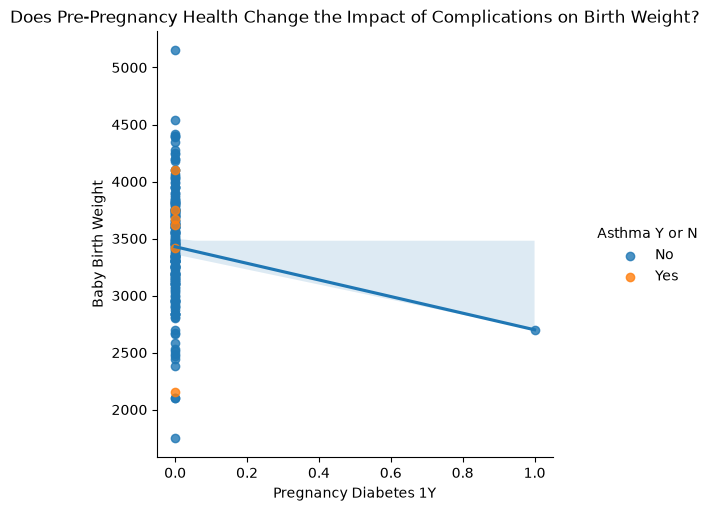

In [10]:
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd_cleaned = pvd.dropna(axis=1, how='any')
pvd_cleaned.columns.tolist()

phys = 'Asthma'
x = 'Pregnancy diabetes 1y'
y = 'Birth weight'

xtraclean = pvd_cleaned[[phys, x, y]].dropna().copy()
xtraclean[x] = xtraclean[x].apply(lambda val: 1 if 'cukrzyca' in str(val).lower() else 0)
xtraclean[phys] = pd.to_numeric(xtraclean[phys], errors='coerce')
xtraclean[y] = pd.to_numeric(xtraclean[y], errors='coerce')
xtraclean = xtraclean.dropna()

xtraclean['Asthma Y or N'] = xtraclean[phys].map({1: 'Yes', 0: 'No'})

sns.lmplot(
    data=xtraclean,
    x=x,
    y=y,
    hue='Asthma Y or N')

plt.title('Does Pre-Pregnancy Health Change the Impact of Complications on Birth Weight?')
plt.xlabel('Pregnancy Diabetes 1Y')
plt.ylabel('Baby Birth Weight')

plt.show()

My overall plan is to examine the Perceived Vulnerability to Disease dataset to explore how extra physiological stress has adverse effects in pregnancy-related complications. I plan to use the columns noting prenatal physiological health in the individuals (Allergies, Asthma, Endometriosis, Diabetes, Hypertension, Thyroid problems, Hormonal Problems) to make a physiological health burden index, and use the columns noting prenatal psychological health (Perceived Stress Scale, Germ Aversion Sum, Infectability sum) to make a psychological health burden index. I will look into individual effects in newborn health (APGAR score, birth weight) but I will create an overall newborn health index to use for general comparisons.. I will then look at pregnancy-related complications (Pregnancy diabetes 1Y, Thyroid gland problems 1Y, Hypertension 1Y) with newborn health outcomes and compare differences among subsets of individuals with better or worse prenatal health.

Expected Outcomes: I expect to see that individuals with worse prenatal health, both physiological and psychological, have compounded adverse health effects during pregnancy on newborn health outcomes. One possible limitation is in examining psychological health, I don't have very much data on this. If I could find a similar dataset that also included anxiety, depression, etc. it could be better to examine the psychological aspect with. In making this first look, I have also discovered that a big limitation is inconsistency of data within my dataset. It is very unlikely that only one individual in this study had asthma, yet in the plot above, only one datapoint shows Yes to having had asthma.

***

**Question 2**

Elijah - Which life circumstances best predict pregnant women's stress: economic status, relationship stability, or whether the pregnancy was planned?


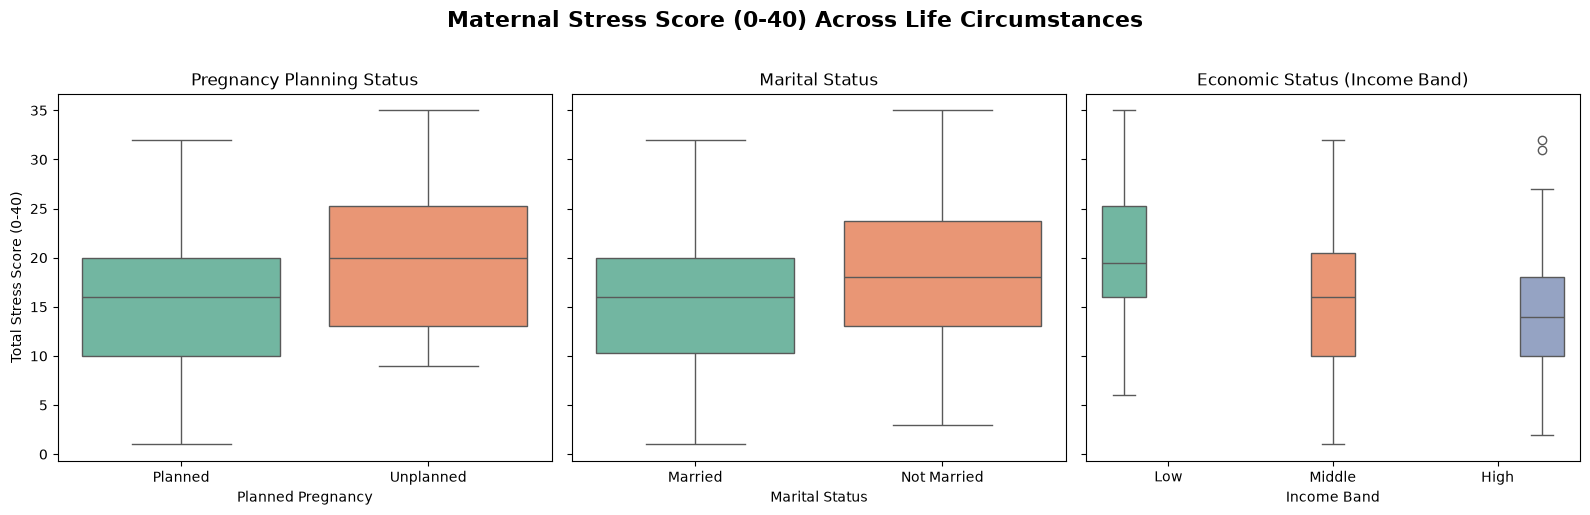

In [5]:
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd_cols = ['SUM (0-40)','Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)','SES self-assessment (1very poor to 7very good)', 'Pregnancy planned (1Y)','Relationship status (1single, 2cohabiting, 3married)', 'Relationship with a biological father of a child']
pvd_clean = pvd[pvd_cols].copy()

stress = ['SUM (0-40)']
Relationship = ['Relationship status (1single, 2cohabiting, 3married)' ]
father = ['Relationship with a biological father of a child']
income = 'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)'
planned = ['Pregnancy planned (1Y)']
pvd_clean['income_band'] = pd.cut(
    pvd_clean[income],
    bins=[0, 3, 5, 8],
    labels=['Low', 'Middle', 'High']
)

# Create clean binary/categorical columns for clear plotting labels
pvd_clean['planned_label'] = pvd_clean['Pregnancy planned (1Y)'].map(
    {1: 'Planned', 0: 'Unplanned'}
)
pvd_clean['married_label'] = pvd_clean[
    'Relationship status (1single, 2cohabiting, 3married)'
].map(lambda x: 'Married' if x == 3 else 'Not Married')

# Set up 1 row, 3 columns multi-panel figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
fig.suptitle(
    'Maternal Stress Score (0-40) Across Life Circumstances',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)

# Panel 1: Stress by Planned/Unplanned
sns.boxplot(
    ax=axes[0],
    data=pvd_clean,
    x='planned_label',
    y='SUM (0-40)',
    hue='planned_label',
    palette='Set2',
    legend=False,
)
axes[0].set_title('Pregnancy Planning Status')
axes[0].set_xlabel('Planned Pregnancy')
axes[0].set_ylabel('Total Stress Score (0-40)')

# Panel 2: Stress by Married / Not Married
sns.boxplot(
    ax=axes[1],
    data=pvd_clean,
    x='married_label',
    y='SUM (0-40)',
    hue='married_label',
    palette='Set2',
    legend=False,
)
axes[1].set_title('Marital Status')
axes[1].set_xlabel('Marital Status')
axes[1].set_ylabel('')  # Shared y-axis

# Panel 3: Stress by Income Band
sns.boxplot(
    ax=axes[2],
    data=pvd_clean,
    x='income_band',
    y='SUM (0-40)',
    hue='income_band',
    palette='Set2',
    order=['Low', 'Middle', 'High'],
    legend=False,
)
axes[2].set_title('Economic Status (Income Band)')
axes[2].set_xlabel('Income Band')
axes[2].set_ylabel('')  # Shared y-axis

plt.tight_layout()
plt.show()

## Research Question Analysis & Proposal Plan

### 1. Variables & Data Preparation
- **Outcome Variable:** Total Stress Score (`SUM (0-40)`).
- **Predictors:** Financial Status (`SES self-assessment` / `income_band`), Pregnancy Planning (`planned_label`), and Relationship Status (`married_label`).
- **Wrangling Applied:** Mapped categorical indicators into clean text labels (`Planned`/`Unplanned`, `Married`/`Not Married`) and binned numeric income into broad ordinal tiers (`Low`, `Middle`, `High`).

### 2. Exploratory Findings (First-Look Boxplots)
- Unplanned pregnancies exhibit noticeably higher median stress scores compared to planned pregnancies.
- Lower income tiers show elevated median stress scores relative to middle and high income groups.
- Unmarried participants display slightly higher median stress scores than married participants.

### 3. Analysis Plan & Next Steps
- **Multiple Regression Analysis:** To determine which life circumstance is the primary independent driver of stress, we will fit a multiple linear regression combining financial status, pregnancy planning, and relationship status. This will isolate the effect of each factor while controlling for the others.
- **Step Beyond FDS I:** We plan to implement a **train/test split (held-out data evaluation)** to assess how accurately a model trained on these baseline life circumstances can predict high vs. low maternal stress levels on unseen data.

### 4. Expected Outcomes
- **If Hunch is Supported:** Financial status / lower income will demonstrate the largest standardized effect ($\beta$) on stress scores when holding pregnancy planning and marital status constant.
- **If Hunch is Wrong:** Pregnancy planning status or marital status will retain a larger significant association with stress scores than income once all variables are evaluated together in the multiple regression model.

***

**Question 3**

Victoria - How does age impact the relationship between socioeconomic status and the health of an individual across both data sets?

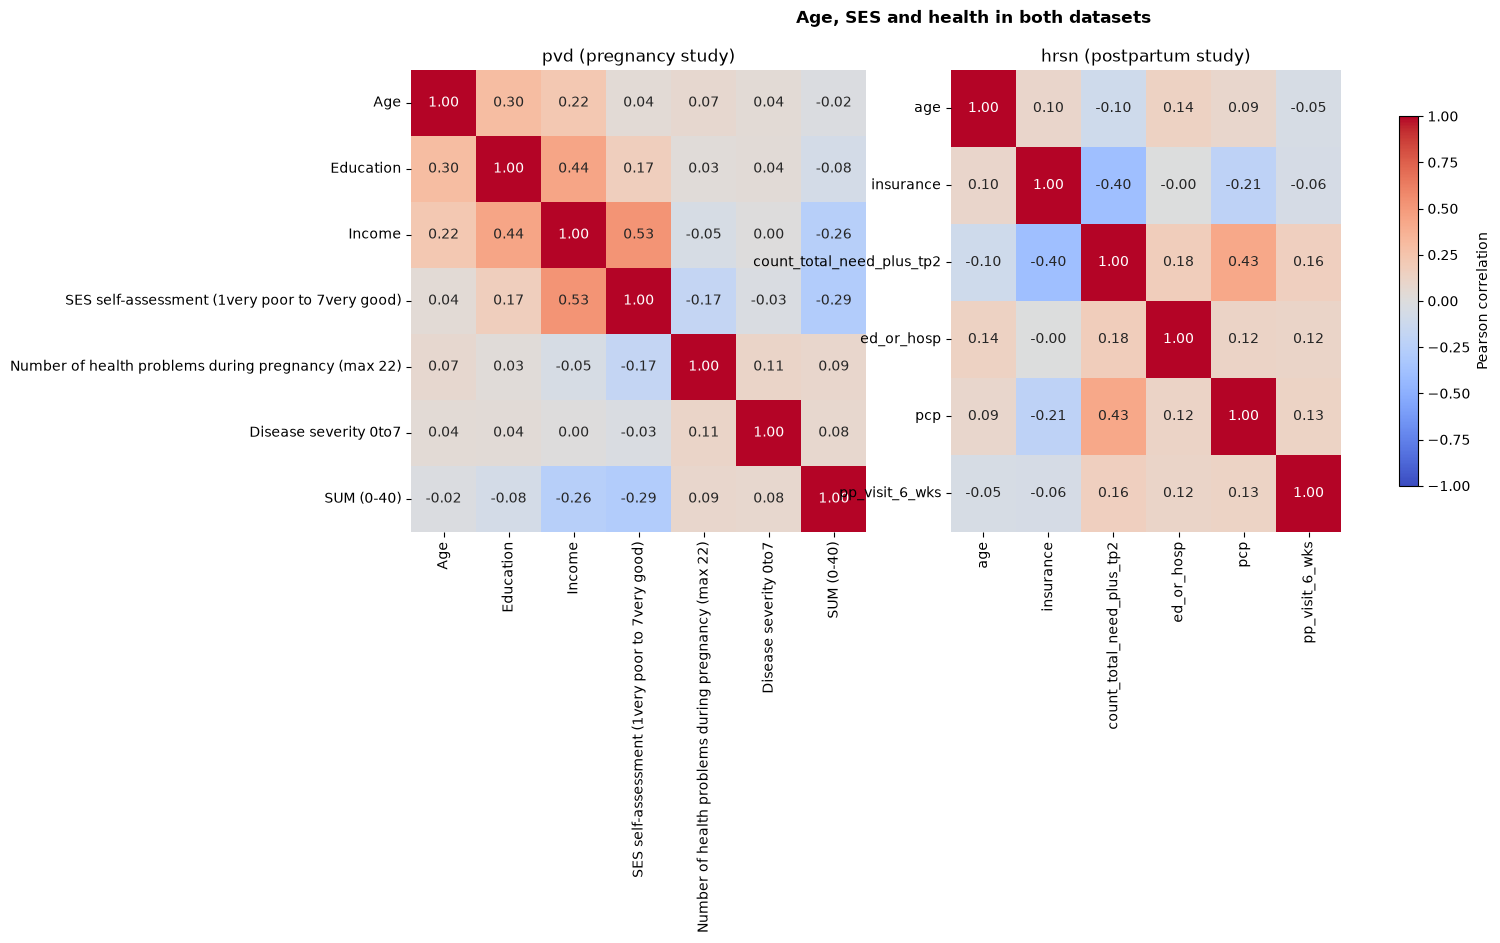

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pvd = pd.read_excel('data/pvdstudy.xlsx')
hrsn = pd.read_csv('data/hrsnstudy.csv')
pvd_cleaned = pvd.dropna(axis=1, how='any')
pvd_cleaned.shape
pvd_cleaned.columns.tolist()
hrsn_cleaned = hrsn.dropna(axis=1, how='any')
hrsn_cleaned.shape
hrsn_cleaned.columns.tolist()

pvd_cols = ['Age','Education','Income','SES self-assessment (1very poor to 7very good)','Number of health problems during pregnancy (max 22)','Disease severity 0to7','SUM (0-40)',]

pvd = pvd.rename(columns={
    'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)': 'Income'})

hrsn_cols = ['age', 'insurance', 'count_total_need_plus_tp2', 'ed_or_hosp', 'pcp', 'pp_visit_6_wks']

# correlation
pvd_cols = pvd[pvd_cols].apply(pd.to_numeric, errors='coerce')
pvd_corr = pvd_cols.corr()

hrsn_cols = hrsn[hrsn_cols].apply(pd.to_numeric, errors='coerce')
hrsn_corr = hrsn_cols.corr()

# heat map
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [7, 6]})
for ax, corr, title in zip(axes, [pvd_corr, hrsn_corr], ['pvd (pregnancy study)', 'hrsn (postpartum study)']):
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)
fig.colorbar(axes[1].collections[0], ax=axes, label='Pearson correlation', shrink=0.8)
fig.suptitle('Age, SES and health in both datasets', fontweight='bold')
plt.show()

I hypothesize that lower SES will be associated with worse health outcomes and that this relationship will be stronger among older participants than younger participants. To investigate this, I will first prepare and describe the data by examining relevant variables, missing values, variable types, and descriptive statistics for age, SES, and health outcomes. I will then define SES and health separately for each dataset, using indicators such as education, income, self-assessed SES, disease severity, social needs, and postpartum health measures where available. For now, heat maps will give an overview of how age, SES and health outcomes relate. In this heatmap above, I can tell how the relationship between age, socioeconomic status, and health across the two datasets interacts and if it would even be useful to look at I will also utilize other plots like scatter plots and violin plots to make more observations of these connections and namely to examine how SES and health vary across age groups before testing whether age changes the relationship between SES and health. I will also examine whether the findings change when using different SES indicators or health outcomes and compare the general patterns across the two datasets while accounting for differences in their populations and measurements.

If my hypothesis is supported, I expect to find that lower SES is associated with worse health outcomes and that this association is stronger among older participants. This would suggest that age may influence the relationship between SES and health in these samples. However, if my hypothesis is not supported, the relationship may be similar across age groups, weaker than expected, absent, or just plain different between the two datasets. I am also keeping in mind the smaller sample sizes, missing data and self-reported measures for this as well.

***